# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170301        # <-- your full roll number
NAME = "Rhythmpreet Singh"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170301   Name: Rhythmpreet Singh   Fingerprint: 0EA9F5E5   Tickets: 13

Ticket_ID                                                                         Ticket_Text
      T01                                       The Matlab is not working. Please resolve it.
      T02                                                      Error code 0x80070005 appears.
      T03                The student portal crashes while opening. Is there another solution?
      T04                      The laptop is showing an error. The same problem occurs again.
      T05 Wifi has stopped syncing when connected to campus Wi-Fi. Is there another solution?
      T06                              The server was working yesterday. It worked yesterday.
      T07                                                         My roll no. is 1023-03-021.
      T08     Printer keeps asking for login after resetting my password. Can you check this?
      T09                                                       W

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [7]:
import pandas as pd
import nltk
import string
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

# Download required resources
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

# Preprocessing function
def process_ticket(text):
    sentences = sent_tokenize(str(text))
    tokens = word_tokenize(str(text))

    punctuation_tokens = [
        t for t in tokens
        if all(c in string.punctuation for c in t)
    ]

    stopword_tokens = [
        t for t in tokens
        if t.lower() in stop_words
    ]

    unique_tokens = set(t.lower() for t in tokens)

    final_tokens = [
        t.lower() for t in tokens
        if t.lower() not in stop_words
        and not all(c in string.punctuation for c in t)
    ]

    return {
        'Sentences': len(sentences),
        'Tokens': len(tokens),
        'Punctuation_Tokens': len(punctuation_tokens),
        'Stopwords': len(stopword_tokens),
        'Unique_Tokens': len(unique_tokens),
        'Final_Tokens': len(final_tokens),
        'Actual_Tokens': tokens,
        'Actual_Punctuation': punctuation_tokens,
        'Actual_Stopwords': stopword_tokens,
        'Actual_Final_Tokens': final_tokens
    }

# Run preprocessing on every ticket
processed = df['Ticket_Text'].apply(process_ticket)

# Create summary table
summary = pd.DataFrame(processed.tolist())

count_columns = [
    'Sentences',
    'Tokens',
    'Punctuation_Tokens',
    'Stopwords',
    'Unique_Tokens',
    'Final_Tokens'
]

table = pd.concat(
    [df['Ticket_ID'].reset_index(drop=True),
     summary[count_columns].reset_index(drop=True)],
    axis=1
)

# Add TOTAL row
total = {'Ticket_ID': 'TOTAL'}
for col in count_columns:
    total[col] = table[col].sum()

table = pd.concat(
    [table, pd.DataFrame([total])],
    ignore_index=True
)

# Display the required table
display(table)

# Display actual tokens for one selected ticket
ticket_id = 'T01'
i = df.index[df['Ticket_ID'] == ticket_id][0]
details = process_ticket(df.loc[i, 'Ticket_Text'])

print("\nSelected Ticket:", ticket_id)
print("Actual tokens:", details['Actual_Tokens'])
print("Punctuation tokens:", details['Actual_Punctuation'])
print("Stopwords:", details['Actual_Stopwords'])
print("Final tokens:", details['Actual_Final_Tokens'])

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Ticket_ID,Sentences,Tokens,Punctuation_Tokens,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,10,2,4,9,4
1,T02,1,5,1,0,5,4
2,T03,2,12,2,4,12,6
3,T04,2,13,2,6,11,5
4,T05,2,15,2,5,15,8
5,T06,2,10,2,3,8,5
6,T07,2,7,2,3,6,2
7,T08,2,15,2,6,15,7
8,T09,1,7,1,3,7,3
9,T10,2,14,2,4,13,8



Selected Ticket: T01
Actual tokens: ['The', 'Matlab', 'is', 'not', 'working', '.', 'Please', 'resolve', 'it', '.']
Punctuation tokens: ['.', '.']
Stopwords: ['The', 'is', 'not', 'it']
Final tokens: ['matlab', 'working', 'please', 'resolve']


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:*

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [12]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re

# Q2(a): Regex extraction
patterns = {
    "Words longer than 5 letters":
        r"\b[A-Za-z]{6,}\b",

    "Numbers, decimals and versions":
        r"(?<![\w.])\d+(?:\.\d+)+(?![\w.])|(?<![\w.])\d+(?![\w.])",

    "Capitalized words":
        r"\b[A-Z][a-zA-Z]*\b",

    "Words beginning with a vowel":
        r"\b[AEIOUaeiou][A-Za-z]*\b"
}

print("Q2(a): REGEX EXTRACTION")

for i, line in enumerate(TEST_LINES, start=1):
    print(f"\nTest line {i}: {line}")
    for label, pattern in patterns.items():
        print(f"{label}: {re.findall(pattern, line)}")


# Q2(b): Regex replacement
# Email: supports dots, hyphens and multiple domain levels.
email_pattern = (
    r"(?<![\w.+-])"
    r"[A-Za-z0-9_%+-]+(?:\.[A-Za-z0-9_%+-]+)*"
    r"@(?:[A-Za-z0-9](?:[A-Za-z0-9-]*[A-Za-z0-9])?\.)+"
    r"[A-Za-z]{2,}"
)

# URL: supports http(s) and www; excludes trailing sentence punctuation.
url_pattern = r"https?://[^\s<>]+|www\.[^\s<>]+"

# Indian phone numbers: +91 with optional separators, or local numbers.
phone_pattern = (
    r"(?<!\w)"
    r"(?:\+91[-.\s]?\d{5}[-.\s]?\d{5}"
    r"|\d{5}[-.\s]\d{5}"
    r"|\d{3}[-.\s]\d{3}[-.\s]\d{4})"
    r"(?!\w)"
)

def replace_sensitive_info(text):
    # Replace email addresses first.
    text = re.sub(email_pattern, "<EMAIL>", text)

    # Remove punctuation at the end of URLs before replacement.
    def replace_url(match):
        url = match.group(0)
        trailing = ""

        while url and url[-1] in ".,;:!?":
            trailing = url[-1] + trailing
            url = url[:-1]

        return "<URL>" + trailing

    text = re.sub(url_pattern, replace_url, text)
    text = re.sub(phone_pattern, "<PHONE>", text)

    return text


print("\nQ2(b): REGEX REPLACEMENT")

for line in TEST_LINES:
    print("\nOriginal:", line)
    print("Replaced:", replace_sensitive_info(line))


print("\nReplacement on generated tickets:")

for _, row in df.iterrows():
    print(row["Ticket_ID"], ":", replace_sensitive_info(row["Ticket_Text"]))

Q2(a): REGEX EXTRACTION

Test line 1: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Words longer than 5 letters: ['helpdesk', 'thapar', 'thapar', 'thapar']
Numbers, decimals and versions: []
Capitalized words: ['Mail']
Words beginning with a vowel: ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']

Test line 2: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Words longer than 5 letters: ['Version']
Numbers, decimals and versions: ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '2.0.1', '95.5', '1']
Capitalized words: ['Call', 'Version', 'Rs']
Words beginning with a vowel: ['or', 'is']

Test line 3: The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
Words longer than 5 letters: []
Numbers, decimals and versions: ['5.30']
Capitalized words: ['The']
Words beginning with a vowel: ['of', 'art', 'isn', 'open', 'in', 'at']



**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:*

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [13]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

custom_pattern = (
    r"""https?://[^\s<>]+|www\.[^\s<>]+"""
    r"""|[A-Za-z0-9_%+-]+(?:\.[A-Za-z0-9_%+-]+)*"""
    r"""@(?:[A-Za-z0-9-]+\.)+[A-Za-z]{2,}"""
    r"""|(?:\+91[-.\s]?\d{5}[-.\s]?\d{5}"""
    r"""|\d{5}[-.\s]\d{5}"""
    r"""|\d{3}[-.\s]\d{3}[-.\s]\d{4})"""
    r"""|\b\d+(?:\.\d+)+\b"""
    r"""|\b[A-Za-z]+(?:['’][A-Za-z]+)+\b"""
    r"""|\b[A-Za-z]+(?:-[A-Za-z]+)+\b"""
    r"""|\b\d+(?:\.\d+)?\b"""
    r"""|\b[A-Za-z]+\b"""
    r"""|[^\w\s]"""
)

my_tokenizer = RegexpTokenizer(custom_pattern)

def my_tokenize(text):
    tokens = my_tokenizer.tokenize(str(text))

    # Detach sentence punctuation from URLs.
    cleaned = []
    for token in tokens:
        if token.startswith(("http://", "https://", "www.")):
            url = token.rstrip(".,;:!?")
            ending = token[len(url):]
            cleaned.append(url)
            cleaned.extend(list(ending))
        else:
            cleaned.append(token)

    return cleaned


print("Q3(a): Custom tokenization on TEST_LINES")

for line in TEST_LINES:
    print("\nText:", line)
    print("Custom:", my_tokenize(line))
    print("NLTK:", word_tokenize(line))


print("\nQ3(b): Tokenization on generated tickets")

for _, row in df.iterrows():
    print("\nTicket:", row["Ticket_ID"])
    print("Text:", row["Ticket_Text"])
    print("Custom:", my_tokenize(row["Ticket_Text"]))
    print("NLTK:", word_tokenize(row["Ticket_Text"]))


print("\nQ3(c): Specific comparison examples")

examples = [
    "isn't",
    "Wi-Fi",
    "state-of-the-art",
    "95.5",
    "2.0.1",
    "it.helpdesk@thapar.edu",
    "https://lms.thapar.edu/help",
    "+91 98765 43210",
    "5.30"
]

for example in examples:
    print("\nExample:", example)
    print("Custom:", my_tokenize(example))
    print("NLTK:", word_tokenize(example))

Q3(a): Custom tokenization on TEST_LINES

Text: Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
Custom: ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
NLTK: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']

Text: Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
Custom: ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175', '-', '239', '-', '3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.']
NLTK: ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']

Text: The state-of-the-art lab isn't open; log-in

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [16]:
import nltk
import pandas as pd

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, LancasterStemmer
from nltk.stem import RegexpStemmer, WordNetLemmatizer

# Download required NLTK resources
for resource in [
    'punkt',
    'punkt_tab',
    'stopwords',
    'averaged_perceptron_tagger',
    'averaged_perceptron_tagger_eng',
    'wordnet',
    'omw-1.4'
]:
    nltk.download(resource, quiet=True)

# Initialize tools
stop_words = set(stopwords.words('english'))
porter = PorterStemmer()
lancaster = LancasterStemmer()
regexp_stemmer = RegexpStemmer('ing$', min=4)
lemmatizer = WordNetLemmatizer()

# Extract unique final tokens directly from df
# This avoids dependency on the 'features' variable from Q1.
unique_final_tokens = set()

for text in df['Ticket_Text'].dropna():
    tokens = word_tokenize(str(text))

    final_tokens = [
        token.lower()
        for token in tokens
        if token.lower() not in stop_words
        and not all(c in ".,!?;:'\"()[]{}-" for c in token)
    ]

    unique_final_tokens.update(final_tokens)

unique_final_tokens = sorted(unique_final_tokens)

# POS tag the unique words
tagged_words = nltk.pos_tag(unique_final_tokens)

def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

# Compare four methods
rows = []

for word, tag in tagged_words:
    pos = get_wordnet_pos(tag)

    p = porter.stem(word)
    l = lancaster.stem(word)
    r = regexp_stemmer.stem(word)
    lemma = lemmatizer.lemmatize(word, pos=pos)

    # Keep only words with differing outputs
    if len({p, l, r, lemma}) > 1:
        rows.append({
            'Word': word,
            'POS': tag,
            'Porter': p,
            'Lancaster': l,
            'Regexp': r,
            'WordNet_Lemma': lemma
        })

comparison_table = pd.DataFrame(
    rows,
    columns=[
        'Word', 'POS', 'Porter',
        'Lancaster', 'Regexp', 'WordNet_Lemma'
    ]
)

print("Unique final tokens:", len(unique_final_tokens))
print("Words with differing outputs:", len(comparison_table))
display(comparison_table)

print(
    "\nRegexp Stemmer justification: "
    "The suffix 'ing' was selected because words such as "
    "'working', 'syncing', and 'uploading' occur in the tickets."
)

Unique final tokens: 46
Words with differing outputs: 31


,Word,POS,Porter,Lancaster,Regexp,WordNet_Lemma
0,another,DT,anoth,anoth,another,another
1,appears,VBZ,appear,appear,appears,appear
2,campus,NN,campu,camp,campus,campus
3,code,NN,code,cod,code,code
4,connected,VBD,connect,connect,connected,connect
5,crashes,NNS,crash,crash,crashes,crash
6,error,NN,error,er,error,error
7,file,NN,file,fil,file,file
8,fixed,VBN,fix,fix,fixed,fix
9,keeps,NNS,keep,keep,keeps,keep



Regexp Stemmer justification: The suffix 'ing' was selected because words such as 'working', 'syncing', and 'uploading' occur in the tickets.


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

Q5(a): Corpus Statistics


,Total Tokens,Unique Tokens,TTR
S1,144.0,77.0,0.5347
S2,118.0,73.0,0.6186
S3,69.0,46.0,0.6667
S4,69.0,45.0,0.6522


Q5(b): Top 10 words in S1


,Word,Frequency
0,.,18
1,The,7
2,?,6
3,is,5
4,it,4
5,Please,3
6,resolve,3
7,portal,3
8,Is,3
9,working,2


Top 10 words in S3


,Word,Frequency
0,please,3
1,resolve,3
2,portal,3
3,working,2
4,error,2
5,student,2
6,opening,2
7,another,2
8,solution,2
9,laptop,2


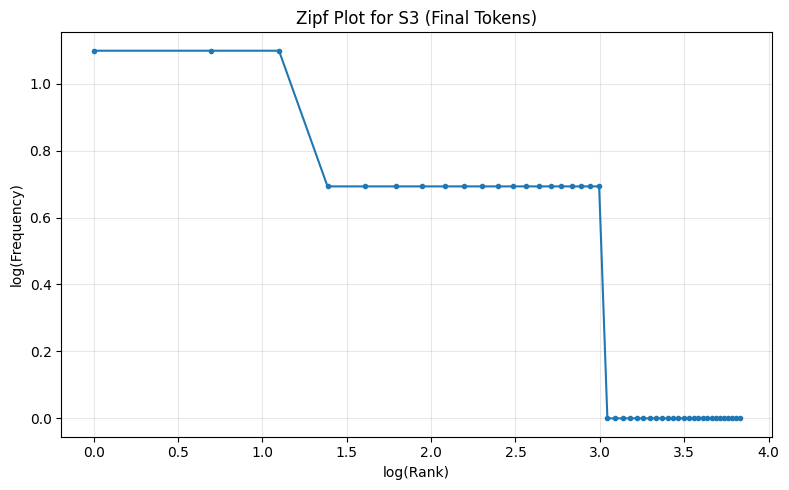

Q5(d): Top 5 bigrams of S1


,Bigram,Frequency
0,"(., Please)",3
1,"(Please, resolve)",3
2,"(resolve, it)",3
3,"(it, .)",3
4,"(., Is)",2


Top 5 bigrams of S3


,Bigram,Frequency
0,"(please, resolve)",3
1,"(student, portal)",2
2,"(another, solution)",2
3,"(problem, occurs)",2
4,"(stopped, syncing)",2


In [17]:
import string
import math
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.util import bigrams

# Initialize
stop_words = set(stopwords.words('english'))
porter = PorterStemmer()

# Create S1, S2, S3 for each ticket
S1_by_ticket = []
S2_by_ticket = []
S3_by_ticket = []

for text in df['Ticket_Text'].fillna(''):
    tokens = word_tokenize(str(text))

    # S1: All tokens
    S1_by_ticket.append(tokens)

    # S2: Tokens without punctuation
    s2 = [
        token for token in tokens
        if not (
            token and all(char in string.punctuation for char in token)
        )
    ]
    S2_by_ticket.append(s2)

    # S3: Remove punctuation and stopwords
    s3 = [
        token.lower() for token in tokens
        if token.lower() not in stop_words
        and not (
            token and all(char in string.punctuation for char in token)
        )
    ]
    S3_by_ticket.append(s3)

# Flatten each corpus for corpus-level statistics
S1 = [t for ticket in S1_by_ticket for t in ticket]
S2 = [t for ticket in S2_by_ticket for t in ticket]
S3 = [t for ticket in S3_by_ticket for t in ticket]

# S4: S3 after Porter stemming
S4 = [porter.stem(t) for t in S3]


# Calculate corpus statistics
def corpus_stats(tokens):
    total = len(tokens)
    unique = len(set(tokens))
    ttr = unique / total if total else 0

    return {
        'Total Tokens': total,
        'Unique Tokens': unique,
        'TTR': round(ttr, 4)
    }

statistics = pd.DataFrame({
    'S1': corpus_stats(S1),
    'S2': corpus_stats(S2),
    'S3': corpus_stats(S3),
    'S4': corpus_stats(S4)
}).T

print("Q5(a): Corpus Statistics")
display(statistics)


# Q5(b): Top 10 words in S1
print("Q5(b): Top 10 words in S1")

display(pd.DataFrame(
    Counter(S1).most_common(10),
    columns=['Word', 'Frequency']
))

# Top 10 words in S3
print("Top 10 words in S3")

display(pd.DataFrame(
    Counter(S3).most_common(10),
    columns=['Word', 'Frequency']
))


# Q5(c): Plot log(rank) vs log(frequency) for S3
frequencies = sorted(Counter(S3).values(), reverse=True)

ranks = list(range(1, len(frequencies) + 1))

log_ranks = [math.log(r) for r in ranks]
log_frequencies = [math.log(f) for f in frequencies]

plt.figure(figsize=(8, 5))
plt.plot(log_ranks, log_frequencies, marker='o', markersize=3)
plt.xlabel('log(Rank)')
plt.ylabel('log(Frequency)')
plt.title('Zipf Plot for S3 (Final Tokens)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Q5(d): Top 5 bigrams within tickets
# This avoids creating bigrams across ticket boundaries.
S1_bigram_counts = Counter()
S3_bigram_counts = Counter()

for tokens in S1_by_ticket:
    S1_bigram_counts.update(bigrams(tokens))

for tokens in S3_by_ticket:
    S3_bigram_counts.update(bigrams(tokens))

print("Q5(d): Top 5 bigrams of S1")

display(pd.DataFrame(
    S1_bigram_counts.most_common(5),
    columns=['Bigram', 'Frequency']
))

print("Top 5 bigrams of S3")

display(pd.DataFrame(
    S3_bigram_counts.most_common(5),
    columns=['Bigram', 'Frequency']
))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:*